### 0. Load Library

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle, os
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV, learning_curve
from scipy.stats import randint, uniform
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, precision_score, recall_score, f1_score, roc_curve, precision_recall_curve, confusion_matrix)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from fastapi import FastAPI
from pydantic import BaseModel, Field

RANDOM_STATE = 42

### 1. Exploratory Data Analysis

In [2]:
train = pd.read_csv("cs-training.csv", index_col=0)
test = pd.read_csv("cs-test.csv", index_col=0)

print("Train shape:", train.shape)
print("Test shape :", test.shape)
train.head()

Train shape: (150000, 11)
Test shape : (101503, 11)


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: fl

In [4]:
train.describe().T

,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0


SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64
SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64


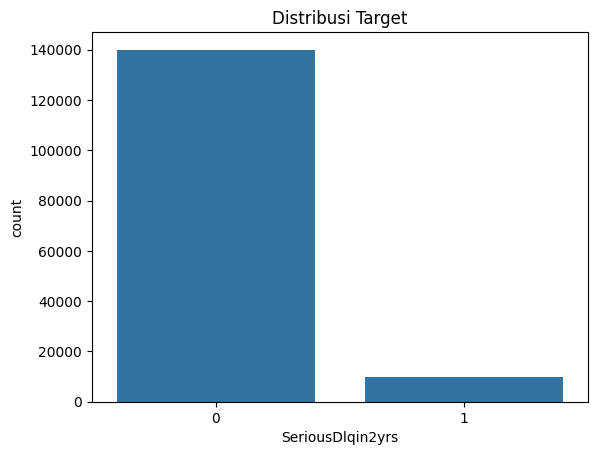

In [5]:
print(train["SeriousDlqin2yrs"].value_counts())
print(train["SeriousDlqin2yrs"].value_counts(normalize=True))

sns.countplot(x="SeriousDlqin2yrs", data=train)
plt.title("Distribusi Target")
plt.show()

- target SeriousDlqin2yrs sangat tidak seimbang (imbalanced). Kelas 0 (tidak mengalami keterlambatan bayar serius dalam 2 tahun) berjumlah 139974 data, sedangkan kelas 1 (mengalami keterlambatan serius) hanya 10026 data, atau kira-kira 6-7% dari total
- Artinya, model berisiko bias ke kelas mayoritas: akurasi bisa tinggi hanya dengan menebak semua sebagai kelas 0, padahal kelas 1 yang justru paling penting dideteksi

In [6]:
missing = pd.DataFrame({
    "missing": train.isnull().sum(),
})
missing[missing["missing"] > 0]

,missing
MonthlyIncome,29731
NumberOfDependents,3924


- MonthlyIncome (29.731 hilang): proporsinya besar, jadi jangan dihapus. Isi dengan median (tahan outlier), dan bisa tambah kolom indikator missing.
- NumberOfDependents (3.924 hilang): proporsinya kecil, cukup diisi modus/median (umumnya 0) atau dihapus

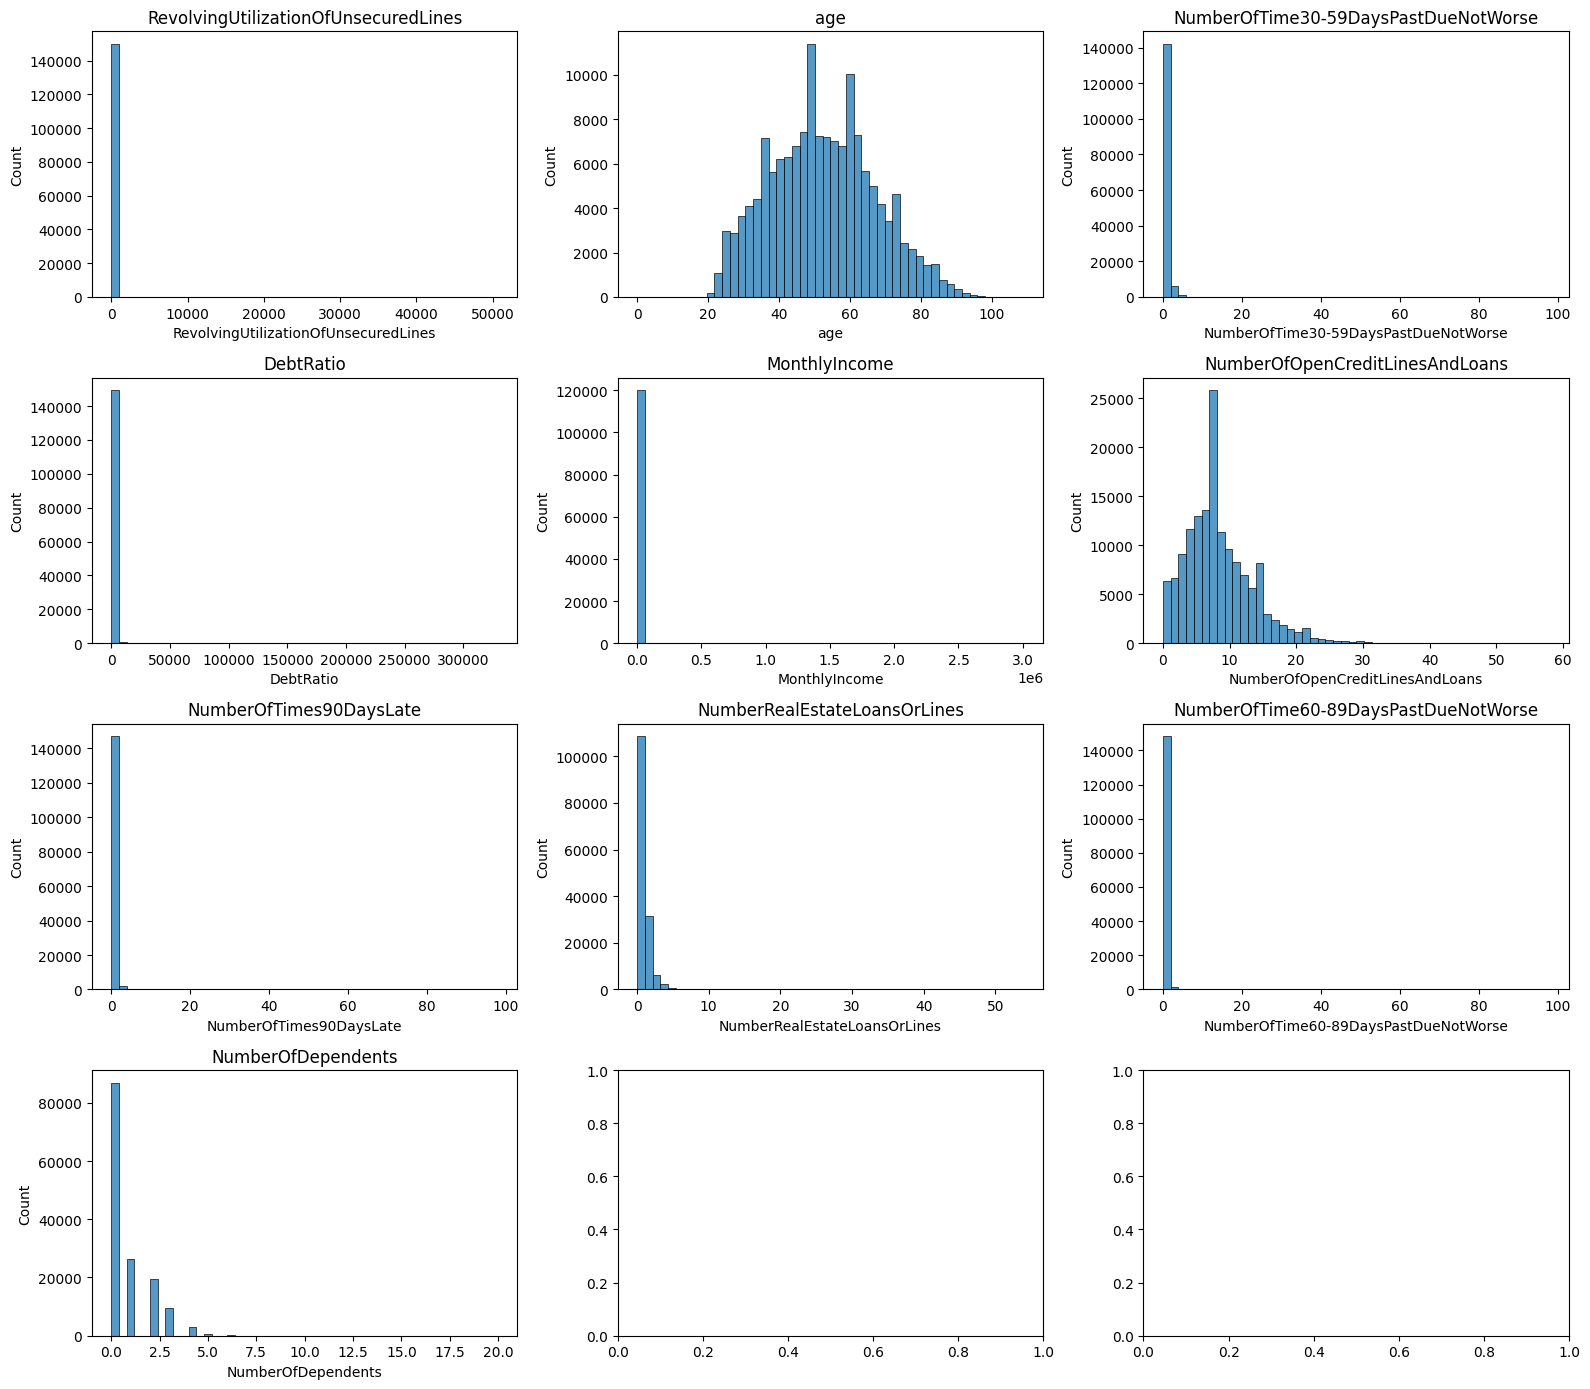

In [7]:
features = [c for c in train.columns if c != "SeriousDlqin2yrs"]

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(train[col].dropna(), bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Sangat miring ke kanan (right-skewed) dengan outlier ekstrem:
- RevolvingUtilizationOfUnsecuredLines (sampai ±50.000, padahal idealnya 0-1)
- DebtRatio (sampai sekitar 300.000)
- MonthlyIncome (sampai sekitar 3 juta)
- Hampir semua data menumpuk di dekat 0, jadi histogram tampak hanya satu batang

In [8]:
print("Age = 0:", (train["age"] == 0).sum())
print("\n")
print("Age min/max:", train["age"].min(), train["age"].max())
print("\n")
late_cols = ["NumberOfTime30-59DaysPastDueNotWorse", "NumberOfTime60-89DaysPastDueNotWorse", "NumberOfTimes90DaysLate"]
for c in late_cols:
    print(train[c].value_counts().sort_index().tail(6))
    print()

Age = 0: 1


Age min/max: 0 109


NumberOfTime30-59DaysPastDueNotWorse
10      4
11      1
12      2
13      1
96      5
98    264
Name: count, dtype: int64

NumberOfTime60-89DaysPastDueNotWorse
7       9
8       2
9       1
11      1
96      5
98    264
Name: count, dtype: int64

NumberOfTimes90DaysLate
13      4
14      2
15      2
17      1
96      5
98    264
Name: count, dtype: int64



- Age = 0 (1 baris): jelas data tidak valid. Hapus baris ini (atau isi median). Dampaknya minim karena hanya 1 baris
- Nilai 96 dan 98 (269 baris): ini kode placeholder/error

Solusi :
- hapus 269 baris tersebut atau ubah 96/98 menjadi NaN lalu imputasi dengan median

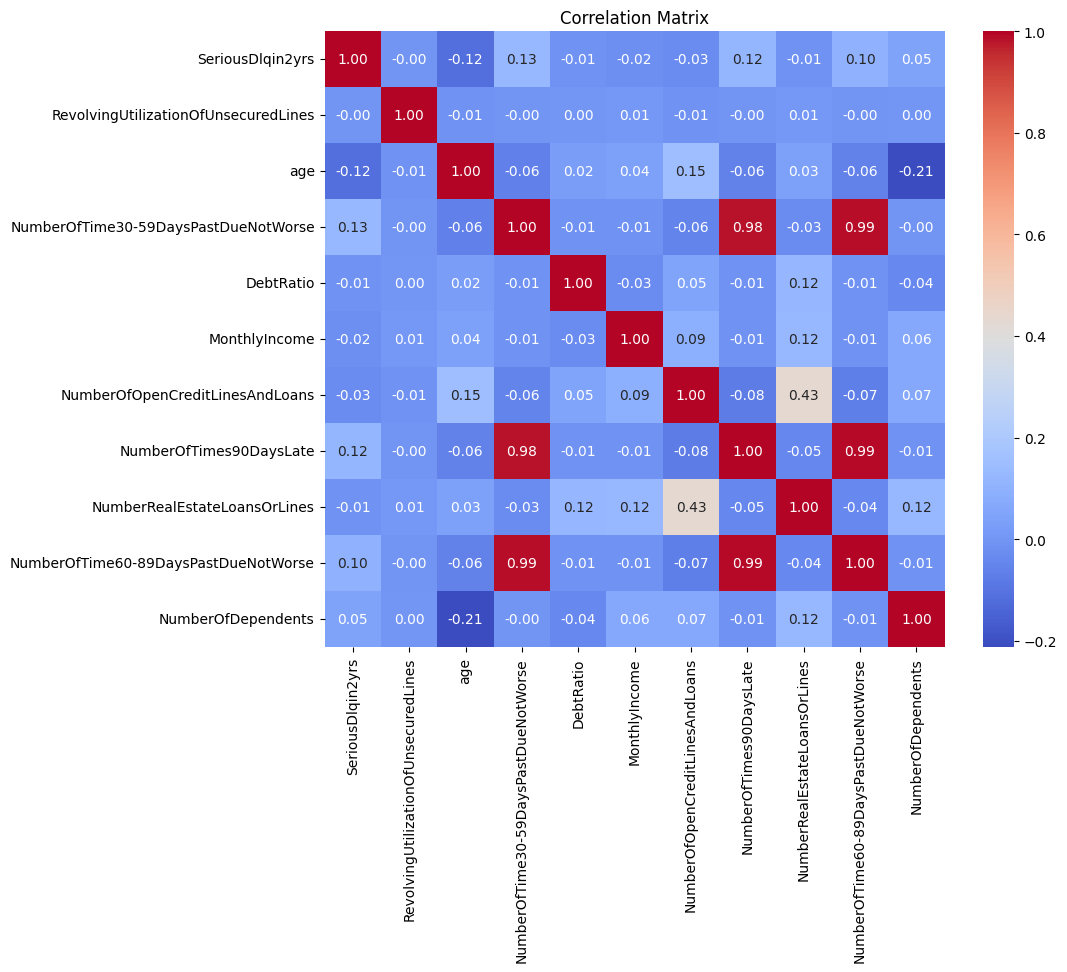

SeriousDlqin2yrs                        1.000000
NumberOfTime30-59DaysPastDueNotWorse    0.125587
NumberOfTimes90DaysLate                 0.117175
NumberOfTime60-89DaysPastDueNotWorse    0.102261
NumberOfDependents                      0.046048
RevolvingUtilizationOfUnsecuredLines   -0.001802
NumberRealEstateLoansOrLines           -0.007038
DebtRatio                              -0.007602
MonthlyIncome                          -0.019746
NumberOfOpenCreditLinesAndLoans        -0.029669
age                                    -0.115386
Name: SeriousDlqin2yrs, dtype: float64

In [9]:
plt.figure(figsize=(10, 8))
sns.heatmap(train.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

train.corr()["SeriousDlqin2yrs"].sort_values(ascending=False)

- Korelasi dengan target (SeriousDlqin2yrs): semuanya lemah. Yang terkuat adalah NumberOfTime30-59DaysPastDueNotWorse (0.125587), NumberOfTimes90DaysLate (0.117175), NumberOfTime60-89DaysPastDueNotWorse (0.102261), dan age (-0.115386, makin muda makin berisiko). Fitur lain hampir tidak berkorelasi linear dengan target

## Interpretasi Preprocessing & Feature Engineering

tugas utama di sini adalah mencegah data leakage jadi melakukan preprocessing dan diterapkan ke validation/test. Yang dikerjakan adalah :

- Pembersihan anomali: age < 18 dan kode 96/98 pada kolom keterlambatan diubah menjadi NaN, lalu diimputasi median
- Imputasi median untuk MonthlyIncome, NumberOfDependents, age, dan 3 kolom keterlambatan
- Capping persentil ke-99 pada RevolvingUtilization, DebtRatio, dan MonthlyIncome agar model tidak didominasi outlier
- 3 flag biner: late_code_flag, income_missing, dependents_missing, untuk mempertahankan informasi dari data bermasalah
- 8 fitur turunan: total_late, weighted_late (bobot 1/2/3 sesuai keparahan), dan has_late merangkum riwayat telat bayar. income_per_person dan debt_amount menggambarkan kemampuan dan beban finansial. credit_lines_per_age, real_estate_ratio, dan age_group menggambarkan profil kredit dan umur

In [10]:
def preprocess(df, medians=None, caps=None):
    df = df.copy()

    df.loc[df["age"] < 18, "age"] = np.nan

    late_cols = ["NumberOfTime30-59DaysPastDueNotWorse",
                 "NumberOfTime60-89DaysPastDueNotWorse",
                 "NumberOfTimes90DaysLate"]
    df["late_code_flag"] = (df[late_cols].isin([96, 98]).any(axis=1)).astype(int)
    for c in late_cols:
        df.loc[df[c].isin([96, 98]), c] = np.nan

    df["income_missing"] = df["MonthlyIncome"].isnull().astype(int)
    df["dependents_missing"] = df["NumberOfDependents"].isnull().astype(int)

    fill_cols = ["MonthlyIncome", "NumberOfDependents", "age"] + late_cols
    if medians is None:
        medians = df[fill_cols].median()
    df[fill_cols] = df[fill_cols].fillna(medians)

    cap_cols = ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio", "MonthlyIncome"]
    if caps is None:
        caps = {c: df[c].quantile(0.99) for c in cap_cols}
    for c in cap_cols:
        df[c] = df[c].clip(upper=caps[c])

    df["total_late"] = (df["NumberOfTime30-59DaysPastDueNotWorse"]
                        + df["NumberOfTime60-89DaysPastDueNotWorse"]
                        + df["NumberOfTimes90DaysLate"])
    df["weighted_late"] = (df["NumberOfTime30-59DaysPastDueNotWorse"] * 1
                           + df["NumberOfTime60-89DaysPastDueNotWorse"] * 2
                           + df["NumberOfTimes90DaysLate"] * 3)
    df["has_late"] = (df["total_late"] > 0).astype(int)
    df["income_per_person"] = df["MonthlyIncome"] / (df["NumberOfDependents"] + 1)
    df["debt_amount"] = df["DebtRatio"] * df["MonthlyIncome"]
    df["credit_lines_per_age"] = df["NumberOfOpenCreditLinesAndLoans"] / df["age"]
    df["real_estate_ratio"] = df["NumberRealEstateLoansOrLines"] / (df["NumberOfOpenCreditLinesAndLoans"] + 1)
    df["age_group"] = pd.cut(df["age"], bins=[0, 30, 40, 50, 60, 200], labels=False)

    return df, medians, caps

In [11]:
y = train["SeriousDlqin2yrs"]
X = train.drop(columns="SeriousDlqin2yrs")

X_tr_raw, X_val_raw, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

X_tr, medians, caps = preprocess(X_tr_raw)
X_val, _, _ = preprocess(X_val_raw, medians, caps)

print(X_tr.shape, X_val.shape)
print("Default rate train:", y_tr.mean(), "| val:", y_val.mean())
X_tr.head()

(120000, 21) (30000, 21)
Default rate train: 0.06684166666666666 | val: 0.06683333333333333


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,...,income_missing,dependents_missing,total_late,weighted_late,has_late,income_per_person,debt_amount,credit_lines_per_age,real_estate_ratio,age_group
57837,0.114987,62.0,0.0,1841.000000,5390.0,5,0.0,1,0.0,2.0,...,1,0,0.0,0.0,0,1796.666667,9.922990e+06,0.080645,0.166667,4
132896,0.008705,73.0,0.0,0.498553,3800.0,6,0.0,1,0.0,0.0,...,0,0,0.0,0.0,0,3800.000000,1.894501e+03,0.082192,0.142857,4
27982,0.214501,32.0,0.0,0.211999,3716.0,8,0.0,0,0.0,2.0,...,0,0,0.0,0.0,0,1238.666667,7.877880e+02,0.250000,0.000000,1
37853,1.000000,60.0,0.0,118.000000,5390.0,5,0.0,0,0.0,0.0,...,1,0,0.0,0.0,0,5390.000000,6.360200e+05,0.083333,0.000000,3
103814,0.230493,60.0,0.0,1.017328,3000.0,10,0.0,1,0.0,0.0,...,0,0,0.0,0.0,0,3000.000000,3.051983e+03,0.166667,0.090909,3


## Model

Model dibangun bertahap dari sederhana ke kompleks agar sumber peningkatan performa bisa ditelusuri :
- Logistic Regression sebagai baseline linier
- Logistic Regression dengan class_weight untuk menangani imbalance
- Random Forest untuk menangkap non-linearitas dan interaksi fitur
- XGBoost dengan scale_pos_weight
- LightGBM dan LightGBM tuned dengan learning rate kecil, num_leaves lebih kecil, dan regularisasi untuk menekan overfitting
- Ensemble rata-rata probabilitas dari model terbaik untuk menstabilkan prediksi
- Setiap model dievaluasi dengan AUC dan threshold optimal (maksimasi F1) yang dipilih di validation set, karena threshold 0.5 hampir selalu suboptimal pada data imbalanced

In [12]:
results = []

def best_threshold_f1(y_true, proba):
    prec, rec, thr = precision_recall_curve(y_true, proba)
    f1 = 2 * prec * rec / (prec + rec + 1e-9)
    idx = np.argmax(f1[:-1])
    return thr[idx]

def evaluate(name, model, X_v, y_v, threshold=None):
    proba = model.predict_proba(X_v)[:, 1]
    auc = roc_auc_score(y_v, proba)

    pred_05 = (proba >= 0.5).astype(int)
    thr = best_threshold_f1(y_v, proba) if threshold is None else threshold
    pred_opt = (proba >= thr).astype(int)

    row = {
        "Model": name,
        "AUC-ROC": auc,
        "Recall@0.5": recall_score(y_v, pred_05),
        "Precision@0.5": precision_score(y_v, pred_05, zero_division=0),
        "F1@0.5": f1_score(y_v, pred_05),
        "Best Thr": thr,
        "Recall@opt": recall_score(y_v, pred_opt),
        "Precision@opt": precision_score(y_v, pred_opt, zero_division=0),
        "F1@opt": f1_score(y_v, pred_opt),
    }
    results.append(row)
    return proba

#### Baseline Logistic Regression

In [13]:
lr = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
lr.fit(X_tr, y_tr)
p_lr = evaluate("Logistic Regression", lr, X_val, y_val)

#### Logistic Regression + class_weight

In [14]:
lr_bal = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced",
                               random_state=RANDOM_STATE))
])
lr_bal.fit(X_tr, y_tr)
p_lr_bal = evaluate("LogReg (balanced)", lr_bal, X_val, y_val)

#### Random Forest

In [15]:
rf = RandomForestClassifier(
    n_estimators=300, max_depth=10, min_samples_leaf=20,
    class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE
)
rf.fit(X_tr, y_tr)
p_rf = evaluate("Random Forest", rf, X_val, y_val)

#### XGBoost

In [16]:
spw = (y_tr == 0).sum() / (y_tr == 1).sum()

xgb = XGBClassifier(
    n_estimators=500, learning_rate=0.03, max_depth=4,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
    scale_pos_weight=spw, eval_metric="auc",
    random_state=RANDOM_STATE, n_jobs=-1
)
xgb.fit(X_tr, y_tr)
p_xgb = evaluate("XGBoost", xgb, X_val, y_val)

#### LightGBM

In [17]:
lgbm = LGBMClassifier(
    n_estimators=600, learning_rate=0.03, num_leaves=31,
    min_child_samples=50, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.8, reg_lambda=1.0,
    is_unbalance=True, random_state=RANDOM_STATE, n_jobs=-1, verbose=-1
)
lgbm.fit(X_tr, y_tr)
p_lgbm = evaluate("LightGBM", lgbm, X_val, y_val)

#### LightGBM tanpa is_unbalance

In [18]:
lgbm2 = LGBMClassifier(
    n_estimators=800, learning_rate=0.02, num_leaves=15,
    min_child_samples=100, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.7, reg_lambda=5.0,
    random_state=RANDOM_STATE, n_jobs=-1, verbose=-1
)
lgbm2.fit(X_tr, y_tr)
p_lgbm2 = evaluate("LightGBM", lgbm2, X_val, y_val)

#### Ensemble (rata-rata probabilitas)

In [19]:
p_ens = (p_xgb + p_lgbm2 + p_rf) / 3

auc_ens = roc_auc_score(y_val, p_ens)
thr = best_threshold_f1(y_val, p_ens)
pred_05 = (p_ens >= 0.5).astype(int)
pred_opt = (p_ens >= thr).astype(int)
results.append({
    "Model": "Ensemble (XGB+LGBM+RF)",
    "AUC-ROC": auc_ens,
    "Recall@0.5": recall_score(y_val, pred_05),
    "Precision@0.5": precision_score(y_val, pred_05, zero_division=0),
    "F1@0.5": f1_score(y_val, pred_05),
    "Best Thr": thr,
    "Recall@opt": recall_score(y_val, pred_opt),
    "Precision@opt": precision_score(y_val, pred_opt, zero_division=0),
    "F1@opt": f1_score(y_val, pred_opt),
})
print("AUC ensemble:", auc_ens)

AUC ensemble: 0.8700203946287167


### Hyperparameter Tuning 

RandomizedSearchCV mencoba beberapa kombinasi acak parameter LightGBM, mengevaluasi tiap kombinasi dengan 3-fold stratified CV (skor AUC), lalu memilih yang terbaik. Dua angka kunci:
- Best CV AUC = nilai rata-rata model terbaik saat diuji makin dekat dengan 1 makin bagus
- Best params = parameter paling bagus akan dipilih otomatis dari pencarian tadi

In [20]:
param_dist = {
    "n_estimators":     randint(300, 900),
    "learning_rate":    uniform(0.01, 0.06),
    "num_leaves":       randint(15, 63),
    "min_child_samples":randint(50, 200),
    "subsample":        uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
    "reg_lambda":       uniform(0.0, 10.0),
}

base_lgbm = LGBMClassifier(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

search = RandomizedSearchCV(
    base_lgbm, param_distributions=param_dist,
    n_iter=15, scoring="roc_auc", cv=cv,
    random_state=RANDOM_STATE, n_jobs=-1, verbose=1,
)
search.fit(X_tr, y_tr)

print("Best CV AUC :", round(search.best_score_, 4))
print("Best params :")
for k, v in search.best_params_.items():
    print(f"   {k}: {v}")

lgbm_tuned = search.best_estimator_
p_lgbm_tuned = evaluate("LightGBM (RandomizedSearchCV)", lgbm_tuned, X_val, y_val)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best CV AUC : 0.8651
Best params :
   colsample_bytree: 0.8170784332632994
   learning_rate: 0.018455453498485756
   min_child_samples: 64
   n_estimators: 364
   num_leaves: 39
   reg_lambda: 9.868869366005173
   subsample: 0.908897907718663


### Learning Curve

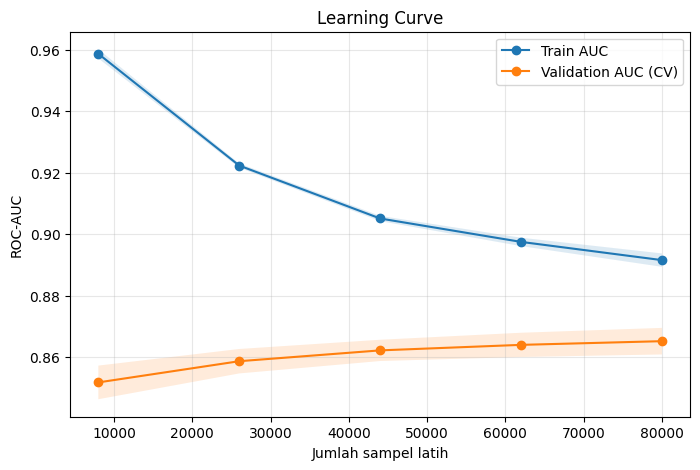

In [21]:
from sklearn.model_selection import learning_curve

lc_model = lgbm_tuned if 'lgbm_tuned' in globals() else lgbm2

train_sizes, train_scores, val_scores = learning_curve(
    lc_model, X_tr, y_tr,
    train_sizes=np.linspace(0.1, 1.0, 5),
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    scoring="roc_auc", n_jobs=-1,
)

train_mean, train_std = train_scores.mean(1), train_scores.std(1)
val_mean,   val_std   = val_scores.mean(1),   val_scores.std(1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, "o-", label="Train AUC")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15)
plt.plot(train_sizes, val_mean, "o-", label="Validation AUC (CV)")
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15)
plt.xlabel("Jumlah sampel latih")
plt.ylabel("ROC-AUC")
plt.title("Learning Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Interpretasi grafik :
- Garis biru turun dari sekitar 0,96 ke 0,89 seiring data training bertambah. jadi makin banyak data, model tidak bisa lagi menghafal semuanya, jadi skor di data latih turun ke angka yang lebih jujur dan tidak mengada ngada
- Garis orange naik dari sekitar 0,85 ke 0,86. Artinya makin banyak data latih, kemampuan model memprediksi data baru makin baik
- Jarak antara kedua garis menyempit. Gap yang mengecil ini pertanda overfitting berkurang, jadi model makin seimbang, bukan sekadar menghafal data training
- Garis validasi masih sedikit menanjak di ujung dan belum benar-benar datar. Ini sinyal bahwa menambah data latih kemungkinan masih bisa menaikkan performa sedikit lagi
- Kesimpulan: model tidak mengalami overfit parah dan skor validasi stabil di sekitar 0,86. Model tidak underfitting maupun overfitting berat


## Result Model (AUC ROC, Recall, Precision, F1-score)

### Tabel perbandingan

In [22]:
res_df = pd.DataFrame(results).set_index("Model").round(4)
res_df.sort_values("AUC-ROC", ascending=False)

,AUC-ROC,Recall@0.5,Precision@0.5,F1@0.5,Best Thr,Recall@opt,Precision@opt,F1@opt
Model,,,,,,,,
LightGBM,0.8701,0.1945,0.6019,0.2940,0.2230,0.4993,0.4069,0.4484
Ensemble (XGB+LGBM+RF),0.8700,0.5920,0.3448,0.4358,0.6117,0.4668,0.4288,0.4470
XGBoost,0.8695,0.7741,0.2191,0.3416,0.7709,0.5282,0.3949,0.4519
LightGBM (RandomizedSearchCV),0.8689,0.1840,0.5990,0.2816,0.2080,0.5142,0.3944,0.4464
Random Forest,0.8677,0.7367,0.2471,0.3701,0.7069,0.5267,0.3805,0.4418
LightGBM,0.8666,0.7511,0.2313,0.3537,0.7610,0.5257,0.3908,0.4483
LogReg (balanced),0.8643,0.7616,0.2215,0.3432,0.8315,0.4509,0.4334,0.4419
Logistic Regression,0.8634,0.1656,0.6125,0.2607,0.2352,0.4728,0.4143,0.4416


- AUC-ROC : kemampuan model untuk meranking nasabah berisiko vs tidak, independen dari threshold. Metrik utama perbandingan model
- Recall : dari semua yang benar-benar menunggak, berapa yang tertangkap. Penting di kredit: melewatkan penunggak (false negative) = kerugian pinjaman
- Precision : dari yang diprediksi menunggak, berapa yang benar. Terlalu rendah = banyak nasabah baik ditolak (kehilangan bisnis)
- F1 : keseimbangan Recall vs Precision, digunakan untuk memilih threshold optimal

Interpretasi tabel perbandingan:
- Semua model punya AUC yang mirip sekitar 0,86 sampai 0,87. Artinya kemampuan dasar meranking nasabah berisiko hampir sama di semua model dengan model paling tinggi LightGBM tuned (0,8701) dan Ensemble (0,8700)
- Setiap model punya karakter berbeda di threshold 0,5 : 
1. XGBoost & Random Forest memiliki Recall tinggi sekitar 0,74 sampai 0,77, tapi Precision rendah 0,22 berarti banyak menangkap penunggak, tapi banyak juga salah tuduh
2. LightGBM tuned & Logistic Regression memiliki Precision tinggi sekitar 0,60, tapi Recall rendah 0,18 berarti jarang salah tuduh, tapi banyak penunggak lolos

- Kesimpulan : Menurut saya model Ensemble adalah pilihan paling aman dengan nilai AUC 0,8700 dan paling seimbang di threshold 0,5 (F1 0,4358, jauh di atas LightGBM tuned yang 0,2940), sehingga lebih stabil tanpa perlu dihyperparameter tuning threshold yang agresif.

### ROC curve

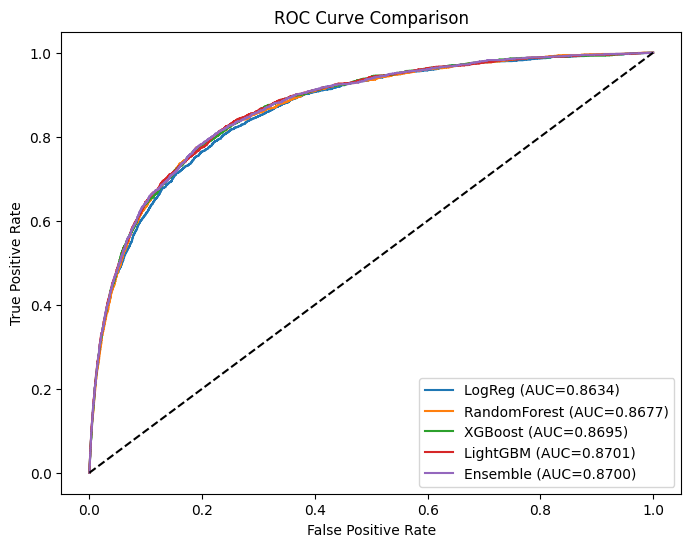

In [23]:
plt.figure(figsize=(8, 6))
for name, p in [("LogReg", p_lr), ("RandomForest", p_rf), ("XGBoost", p_xgb),
                ("LightGBM", p_lgbm2), ("Ensemble", p_ens)]:
    fpr, tpr, _ = roc_curve(y_val, p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_val, p):.4f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

Interpretasi ROC Curve:
- Semua kurva jauh di atas garis putus-putus (tebak acak), jadi semua model jelas berguna
- Kurva kelima model hampir sama, performanya juga hampir setara, tidak ada yang unggul yang mencolok
- Bentuk kurva menanjak tajam di awal, berarti model bisa menangkap banyak penunggak sambil menjaga kesalahan tetap rendah tanda - tanda model yang sehat

### Confusion matrix (model terbaik)

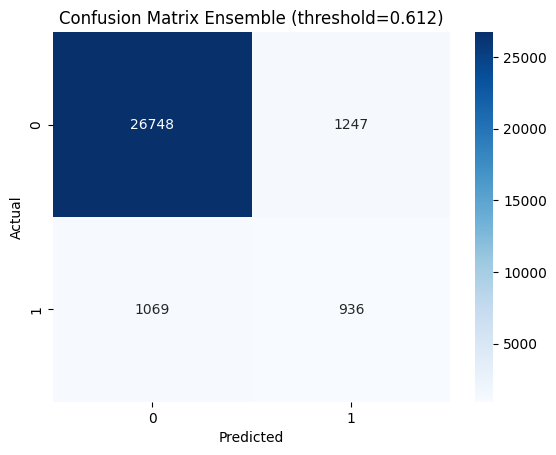

In [24]:
thr_best = best_threshold_f1(y_val, p_ens)
cm = confusion_matrix(y_val, (p_ens >= thr_best).astype(int))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title(f"Confusion Matrix Ensemble (threshold={thr_best:.3f})")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

Interpretasi Confusion Matrix :
- 26.748 benar diprediksi "tidak menunggak" dan 936 benar diprediksi "menunggak", menurut saya ini prediksi yang lumayan bagus
- 1.247 salah tuduh (sebenarnya aman, diprediksi menunggak) nasabah baik yang berpotensi ditolak
- 1.069 penunggak lolos (sebenarnya menunggak, diprediksi aman) jadi ini yang paling berisiko bagi pemberi pinjaman

### Feature importance

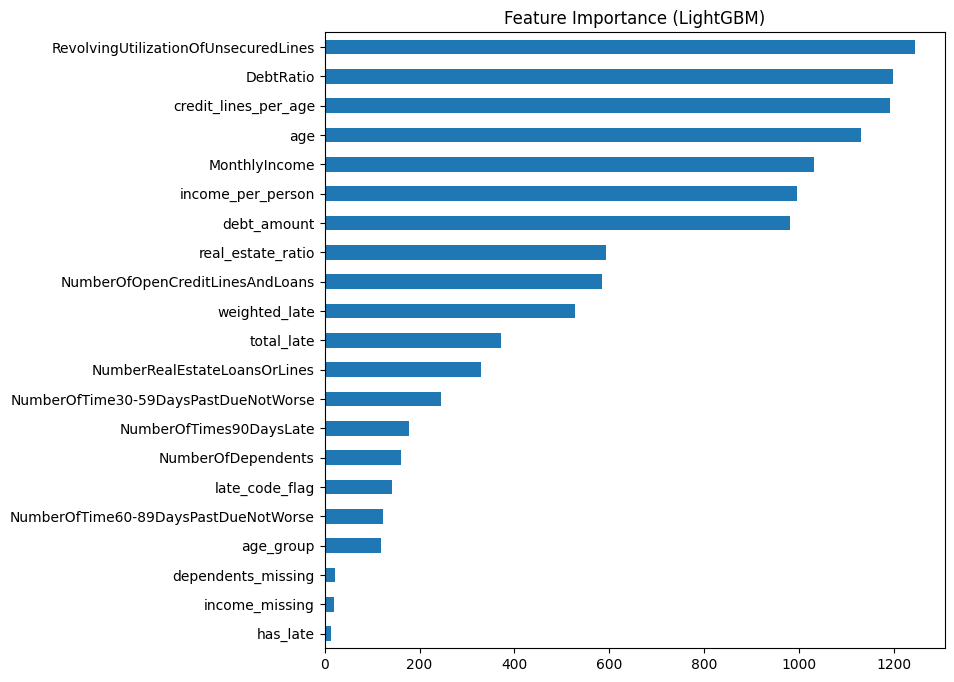

In [25]:
imp = pd.Series(lgbm2.feature_importances_, index=X_tr.columns).sort_values()
imp.plot(kind="barh", figsize=(8, 8), title="Feature Importance (LightGBM)")
plt.show()

Interpretasi Feature Importance :
- Fitur paling berpengaruh: RevolvingUtilizationOfUnsecuredLines
- Fitur yang dibua terbukti ada: credit_lines_per_age, income_per_person, dan debt_amount masuk didalam visualisasi artinya feature engineering beguna dan dipakai
- age dan MonthlyIncome juga kuat nasabah lebih muda / berpenghasilan rendah cenderung lebih berisiko
- flag (late_code_flag, income_missing, dependents_missing, has_late) paling bawah jadi pengaruhnya kecil, menurut saya itu wajar karena dipakai hanya untuk penanda tambahan, bukan sinyal utama
- Kesimpulan : menruut saya model mengambil keputusan berdasarkan faktor yang logis (pemakaian kredit, beban utang, usia, pendapatan), jadi hasilnya bisa dipercaya dan dapat dijelaskan

In [26]:
X_full, med_full, caps_full = preprocess(X)
X_test_full, _, _ = preprocess(test.drop(columns="SeriousDlqin2yrs"), med_full, caps_full)
X_test_full = X_test_full[X_full.columns]

spw_full = (y == 0).sum() / (y == 1).sum()

final_xgb = XGBClassifier(
    n_estimators=500, learning_rate=0.03, max_depth=4,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
    scale_pos_weight=spw_full, eval_metric="auc",
    random_state=RANDOM_STATE, n_jobs=-1
).fit(X_full, y)

final_lgbm = LGBMClassifier(
    n_estimators=800, learning_rate=0.02, num_leaves=15,
    min_child_samples=100, subsample=0.8, subsample_freq=1,
    colsample_bytree=0.7, reg_lambda=5.0,
    random_state=RANDOM_STATE, n_jobs=-1, verbose=-1
).fit(X_full, y)

final_rf = RandomForestClassifier(
    n_estimators=300, max_depth=10, min_samples_leaf=20,
    class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE
).fit(X_full, y)

In [27]:
from scipy.stats import rankdata

preds = [m.predict_proba(X_test_full)[:, 1] for m in (final_xgb, final_lgbm, final_rf)]
ranks = np.mean([rankdata(p) / len(p) for p in preds], axis=0)

submission = pd.DataFrame({"Id": test.index, "Probability": ranks})
submission.to_csv("submission.csv", index=False)
print(submission.shape)
submission.head()

(101503, 2)


,Id,Probability
0,1,0.755127
1,2,0.666296
2,3,0.422411
3,4,0.801149
4,5,0.835949


## Kesimpulan

- Model terpilih: Ensemble (rank-average XGBoost + LightGBM tuned + Random Forest). AUC-nya praktis setara dengan model terbaik, tetapi dipilih karena memberi trade-off Recall/Precision paling seimbang (F1 tertinggi di threshold 0,5) dan paling stabil karena menggabungkan beberapa algoritma serta meredam kesalahan masing-masing model
- Fitur paling berpengaruh adalah pemanfaatan kredit (RevolvingUtilizationOfUnsecuredLines), rasio utang (DebtRatio), dan fitur buatan credit_lines_per_age dan membuktikan feature engineering menambah nilai nyata.

In [35]:
os.makedirs("artifacts", exist_ok=True)

artifacts = {
    "xgb": xgb,
    "lgbm": lgbm2,
    "rf": rf,
    "medians": medians,
    "caps": caps,
    "feature_cols": list(X_tr.columns),
    "threshold": float(best_threshold_f1(y_val, p_ens)),
}

with open("artifacts/model.pkl", "wb") as f:
    pickle.dump(artifacts, f)

print("Tersimpan:", os.path.getsize("artifacts/model.pkl") / 1e6, "MB")

Tersimpan: 21.026113 MB
